# Denoising autoencoder on CIFAR-10

A small convolutional autoencoder that gets CIFAR-10 images with Gaussian noise added and learns to reconstruct the clean image, trained with BCE loss. No metric, just a look at one reconstructed image at the end.

In [71]:
from datasets import load_dataset
import torch
import torchvision.transforms.v2 as v2
import torch.nn as nn

# Load the dataset
dataset = load_dataset("uoft-cs/cifar10")

# View the dataset structure
print(dataset)

README.md:   0%|          | 0.00/5.16k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/120M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/23.9M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})


In [141]:
class GaussDataset():
  def __init__(self, dataset):
    self.dataset = dataset
    self.trans = v2.Compose([
    v2.ToTensor(),
    v2.GaussianNoise(mean=0.0, sigma=0.1)
])
  def __len__(self):
    return len(self.dataset)
  def __getitem__(self, idx):
    m = self.trans(self.dataset[idx])
    return (m['img'], m['label'])

class NormDataset():
  def __init__(self, dataset):
    self.dataset = dataset
    self.trans = v2.Compose([
    v2.ToTensor()
])
  def __len__(self):
    return len(self.dataset)
  def __getitem__(self, idx):
    m = self.trans(self.dataset[idx])
    return (m['img'], m['label'])

class TrainDataset():
  def __init__(self, dataset):
    self.dataset = dataset
    self.trans1 = v2.Compose([
    v2.ToTensor()
])
    self.trans2 = v2.Compose([
    v2.ToTensor(),
    v2.GaussianNoise(mean=0.0, sigma=0.07)
])
  def __len__(self):
    return len(self.dataset)
  def __getitem__(self, idx):
    a = self.trans1(self.dataset[idx])
    b = self.trans2(self.dataset[idx])
    return (a['img'], b['img'], a['label'])

In [142]:
from numpy import test
train_g = GaussDataset(dataset['train'])
train_norm = NormDataset(dataset['train'])
test_g = GaussDataset(dataset['test'])
test_norm = NormDataset(dataset['test'])
train = TrainDataset(dataset['train'])
test = TrainDataset(dataset['test'])

/usr/local/lib/python3.12/dist-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


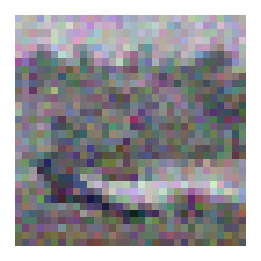

In [144]:
from PIL import Image
import matplotlib.pyplot as plt

# 1. Open the image using PIL
#img = train_norm[8][0]
img = train[0][1]

# 2. Pass the PIL image directly into Matplotlib
img_to_show = img.permute(1, 2, 0)

# Note: If it's a NumPy array instead, use:
# img_to_show = np.transpose(img, (1, 2, 0))

# 4. Plot with high quality settings
plt.figure(figsize=(2, 2), dpi=150)  # CIFAR-10 is tiny (32x32), boosting DPI keeps it crisp
plt.imshow(img_to_show)
plt.axis('off')  # Hides the pixel coordinate axes
plt.show()

In [145]:
"""
        # 16x8x8 -> 48x4x4
        nn.Conv2d(16, 48, kernel_size=4, stride=2, padding=1)
        nn.BatchNorm2d(48),
        nn.ReLU()
        """

class DAE(nn.Module):
  def __init__(self):
    super().__init__()
    self.encoder = nn.Sequential(
        # 3x32x32 -> 16x16x16
        nn.Conv2d(3, 16, kernel_size=4, stride=2, padding=1),
        nn.BatchNorm2d(16),
        nn.ReLU(),
        # 16x16x16 -> 32x8x8
        nn.Conv2d(16, 32, kernel_size=4, stride=2, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU()
    )
    self.decoder = nn.Sequential(
        #32x8x8 -> 16x16x16
    nn.ConvTranspose2d(32, 16, kernel_size=3, stride=2, padding=1, output_padding=1),
    ### output padding is when it does not know whether to upsacel to 7x7 or to 8x8 like when Con2d same shapes like 7x7 and 8x8
    ### downscale to save window sizer
    nn.BatchNorm2d(16),
    nn.ReLU(),
    nn.ConvTranspose2d(16, 3, kernel_size = 3, stride = 2, padding=1, output_padding=1),
    nn.BatchNorm2d(3),
    nn.Sigmoid()
    )
  def forward(self, x):
    z = self.encoder(x)
    x_hat = self.decoder(z)
    return x_hat

In [147]:
from torch.utils.data import DataLoader
model = DAE()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4, weight_decay = 0.02)
train_loader = DataLoader(train, batch_size = 64, shuffle = True, num_workers = 2)
test_loader = DataLoader(test, batch_size = 64, shuffle = True, num_workers = 2)

In [160]:
import torch.nn.functional as F
from tqdm import tqdm
epochs = 3
#F.binary_cross_entropy(x_hat, x_flat, reduction="sum")

model.to('cuda')
for epoch in range(epochs):
  model.train()
  loss_total = 0.0
  for idx, batch in enumerate(tqdm(train_loader)):
    X_normal = batch[0].to('cuda')
    X_gaussian = batch[1].to('cuda')
    X_labels = batch[2].to('cuda')

    outputs = model(X_gaussian).flatten(1)
    outs_labels = X_normal.flatten(1)

    loss = F.binary_cross_entropy(outputs, outs_labels, reduction = "sum")

    optimizer.zero_grad()
    loss.backward()

    optimizer.step()
    loss_total += loss.item()
    if idx % 500 == 0:
      print(loss.item())
  print(loss_total)

torch.Size([64, 3072])


In [167]:
zem = next(iter(test_loader))
with torch.no_grad():
  outputs = model(zem[0].to('cuda'))
print(outputs.shape)

torch.Size([64, 3, 32, 32])


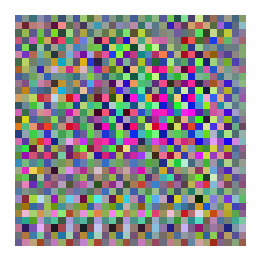

In [169]:
from PIL import Image
import matplotlib.pyplot as plt

# 1. Open the image using PIL
#img = train_norm[8][0]
img = outputs[0].cpu()

# 2. Pass the PIL image directly into Matplotlib
img_to_show = img.permute(1, 2, 0)

# Note: If it's a NumPy array instead, use:
# img_to_show = np.transpose(img, (1, 2, 0))

# 4. Plot with high quality settings
plt.figure(figsize=(2, 2), dpi=150)  # CIFAR-10 is tiny (32x32), boosting DPI keeps it crisp
plt.imshow(img_to_show)
plt.axis('off')  # Hides the pixel coordinate axes
plt.show()